# Cybersecurity Threat Analytics
A focused Python and SQLite investigation for a hypothetical Security Operations Center (SOC).

The supplied file contains **synthetic security events**, not verified incidents. Counts describe this file, not exposure-adjusted risk. Dataset attribution is retained from the original notebook: [Incribo cybersecurity attacks](https://www.kaggle.com/datasets/teamincribo/cyber-security-attacks); the downloaded file's provenance and generation process have not been independently verified.

Five questions guide the analysis:
1. How do event categories vary across network segments and devices?
2. Are severity labels associated with recorded response actions?
3. How do monthly volumes and response shares change, accounting for partial periods?
4. Which recorded associations have enough effect size to merit further investigation?
5. Can the available features predict protocol better than a simple baseline in high-anomaly events?

The original notebook remains unchanged. This version retains its geographic and temporal investigations and protocol target, while replacing unsupported operational claims with measured evidence.

## 1. Data Understanding and Preparation
We first audit the supplied records. Missing detection fields are not automatically evidence that no detection occurred. No event is removed merely because it has a blank optional field.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import re
import sqlite3
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from IPython.display import display, Markdown
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Support launching Jupyter from either the project root or notebooks/.
project_root = Path.cwd()
if not (project_root / "data/cybersecurity_attacks.csv").exists():
    project_root = project_root.parent
assert (project_root / "data/cybersecurity_attacks.csv").exists(), "Open this project first."

SEED = 42
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 15)
print("Python:", sys.version.split()[0], "| SQLite:", sqlite3.sqlite_version)
display(pd.Series({package: metadata.version(package) for package in [
    "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn",
    "geopandas", "shapely", "pyogrio", "pyproj", "nbformat", "nbclient", "ipykernel",
]}, name="installed_version").to_frame())

Python: 3.9.6 | SQLite: 3.51.0


,installed_version
pandas,2.3.3
numpy,2.0.2
scipy,1.13.1
scikit-learn,1.6.1
matplotlib,3.9.4
seaborn,0.13.2
geopandas,1.0.1
shapely,2.0.7
pyogrio,0.10.0
pyproj,3.6.1


In [2]:
raw = pd.read_csv(project_root / "data/cybersecurity_attacks.csv")
print(f"Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print(f"Exact duplicate rows: {raw.duplicated().sum():,}")
display(raw.head(3))

audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100).round(2),
    "unique_nonmissing": raw.nunique(),
})
display(audit)

Raw shape: 40,000 rows × 25 columns
Exact duplicate rows: 0


,Timestamp,Source IP Address,Destination IP Address,Source Port,Destination Port,Protocol,Packet Length,...,Device Information,Network Segment,Geo-location Data,Proxy Information,Firewall Logs,IDS/IPS Alerts,Log Source
0,2023-05-30 6:33:58,103.216.15.12,84.9.164.252,31225,17616,ICMP,503,...,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment A,"Phagwara, Bihar",150.9.97.135,Log Data,NaN,Server
1,2020-08-26 7:08:30,78.199.217.198,66.191.137.154,17245,48166,ICMP,1174,...,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment B,"Katihar, Bihar",NaN,Log Data,NaN,Firewall
2,2022-11-13 8:23:25,63.79.210.48,198.219.82.17,16811,53600,UDP,306,...,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,Segment C,"Shahjahanpur, Bihar",114.133.48.179,Log Data,Alert Data,Firewall


,dtype,missing,missing_pct,unique_nonmissing
Timestamp,object,0,0.00,39997
Source IP Address,object,0,0.00,40000
Destination IP Address,object,0,0.00,40000
Source Port,int64,0,0.00,29761
Destination Port,int64,0,0.00,29895
Protocol,object,0,0.00,3
Packet Length,int64,0,0.00,1437
Packet Type,object,0,0.00,2
Traffic Type,object,0,0.00,3
Payload Data,object,0,0.00,40000


Cleaning is deliberately limited: standardize column names, trim surrounding text whitespace, remove only exact duplicate rows, and parse timestamps explicitly. Validate numeric ranges and categorical domains before analysis. Preserve packet lengths and ports that the original notebook dropped.

The original description swaps some fields: `Attack Signature` contains pattern labels; `Action Taken` contains Blocked/Logged/Ignored; `Alerts/Warnings` contains an alert marker or a blank. Segment A/B/C have no verified business definitions, so they retain their supplied labels.

In [3]:
events = raw.copy()
events.columns = (events.columns.str.lower()
                  .str.replace(r"[ /-]+", "_", regex=True))
text_columns = events.select_dtypes(include="object").columns
whitespace_changes = 0
for column in text_columns:
    trimmed = events[column].str.strip()
    whitespace_changes += int((events[column].notna() & events[column].ne(trimmed)).sum())
    events[column] = trimmed.replace("", np.nan)

duplicates_removed = int(events.duplicated().sum())
events = events.drop_duplicates().reset_index(drop=True)
events["timestamp"] = pd.to_datetime(events["timestamp"], errors="coerce")
assert events["timestamp"].notna().all(), "Inspect invalid timestamps before proceeding."

valid_domains = {
    "protocol": {"TCP", "UDP", "ICMP"},
    "packet_type": {"Data", "Control"},
    "traffic_type": {"HTTP", "DNS", "FTP"},
    "attack_type": {"DDoS", "Malware", "Intrusion"},
    "severity_level": {"Low", "Medium", "High"},
    "action_taken": {"Blocked", "Logged", "Ignored"},
    "network_segment": {"Segment A", "Segment B", "Segment C"},
    "attack_signature": {"Known Pattern A", "Known Pattern B"},
}
for column, allowed in valid_domains.items():
    assert events[column].notna().all(), f"Missing category in {column}"
    assert set(events[column].unique()) <= allowed, f"Unexpected category in {column}"

numeric_ranges = {
    "source_port": (0, 65535), "destination_port": (0, 65535),
    "packet_length": (1, 65535), "anomaly_scores": (0, 100),
}
range_audit = []
for column, (lower, upper) in numeric_ranges.items():
    invalid = ~events[column].between(lower, upper)
    range_audit.append({"feature": column, "missing_or_out_of_range": int(invalid.sum())})
    assert not invalid.any(), f"Inspect invalid values in {column}"

display(pd.DataFrame(range_audit))
display(events[list(numeric_ranges)].describe().round(2))
print(f"Whitespace values trimmed: {whitespace_changes:,}; exact duplicates removed: {duplicates_removed:,}")
print("Observed timestamp range:", events.timestamp.min(), "to", events.timestamp.max())

,feature,missing_or_out_of_range
0,source_port,0
1,destination_port,0
2,packet_length,0
3,anomaly_scores,0


,source_port,destination_port,packet_length,anomaly_scores
count,40000.00,40000.00,40000.00,40000.00
mean,32970.36,33150.87,781.45,50.11
std,18560.43,18574.67,416.04,28.85
min,1027.00,1024.00,64.00,0.00
25%,16850.75,17094.75,420.00,25.15
50%,32856.00,33004.50,782.00,50.34
75%,48928.25,49287.00,1143.00,75.03
max,65530.00,65535.00,1500.00,100.00


Whitespace values trimmed: 0; exact duplicates removed: 0
Observed timestamp range: 2020-01-01 00:43:27 to 2023-10-11 19:34:23


Derived features retain the original timestamp resolution and separate city/state labels. User-agent parsing is a coarse device proxy; Android must be checked before Linux. These labels describe the supplied strings, not verified hardware.

Binary detection features mean **a marker is recorded**. A zero means the field is blank, with unknown detection status. They are used descriptively and excluded from the predictive model because their timing is undocumented.

In [4]:
events["event_date"] = events.timestamp.dt.normalize()
events["hour"] = events.timestamp.dt.hour
events["weekday"] = events.timestamp.dt.dayofweek
events["month"] = events.timestamp.dt.month
events["hour_sin"] = np.sin(2 * np.pi * events.hour / 24)
events["hour_cos"] = np.cos(2 * np.pi * events.hour / 24)
events["month_sin"] = np.sin(2 * np.pi * (events.month - 1) / 12)
events["month_cos"] = np.cos(2 * np.pi * (events.month - 1) / 12)

locations = events.geo_location_data.str.rsplit(",", n=1, expand=True)
events["location_city"] = locations[0].str.strip()
events["location_state"] = locations[1].str.strip()
assert events.location_state.notna().all()

agent = events.device_information.fillna("")
events["os_family"] = np.select([
    agent.str.contains("Android", case=False),
    agent.str.contains("iPhone|iPad|iPod", case=False, regex=True),
    agent.str.contains("Windows", case=False),
    agent.str.contains("Macintosh", case=False),
    agent.str.contains("Linux", case=False),
], ["Android", "iOS", "Windows", "macOS", "Linux"], default="Other/unknown")
events["device_type"] = events.os_family.map({
    "Android": "Mobile/Tablet", "iOS": "Mobile/Tablet",
    "Windows": "Laptop/Desktop", "macOS": "Laptop/Desktop", "Linux": "Laptop/Desktop",
}).fillna("Other/unknown")

for column in ["source_port", "destination_port"]:
    events[column + "_band"] = pd.cut(
        events[column], bins=[-1, 1023, 49151, 65535],
        labels=["0–1023", "1024–49151", "49152–65535"],
    ).astype(str)

for column, marker in {
    "malware_indicators": "IoC Detected", "alerts_warnings": "Alert Triggered",
    "firewall_logs": "Log Data", "ids_ips_alerts": "Alert Data",
}.items():
    assert set(events[column].dropna().unique()) <= {marker}
    events[column + "_recorded"] = events[column].eq(marker).astype(int)

display(events.groupby("os_family").agg(
    events=("protocol", "size"), mean_anomaly=("anomaly_scores", "mean")
).round(2))
icmp_with_ports = int((events.protocol.eq("ICMP") & events.source_port.notna()
                       & events.destination_port.notna()).sum())
print(f"ICMP rows with both port fields populated: {icmp_with_ports:,}")

,events,mean_anomaly
os_family,,
Android,3289,50.14
Linux,7171,50.51
Windows,17953,50.02
iOS,5774,50.17
macOS,5813,49.84


ICMP rows with both port fields populated: 18,370


Important quality limits: ICMP has no TCP/UDP-style ports, so the populated port fields reveal a synthetic inconsistency. City/state pairings are not geocoded or validated; IP-derived location accuracy cannot be checked. Records contain only labeled attack categories, with no benign class or verified outcomes. Neither attack detection performance nor successful prevention can be estimated from this file.

## 2. Exploratory Data Analysis and SQL
**Question 1: How are categories distributed across segments and devices?** Use within-group percentages so that larger groups do not automatically appear to have a different attack mix. Event volume has no denominator for monitored endpoints, traffic, or customers.

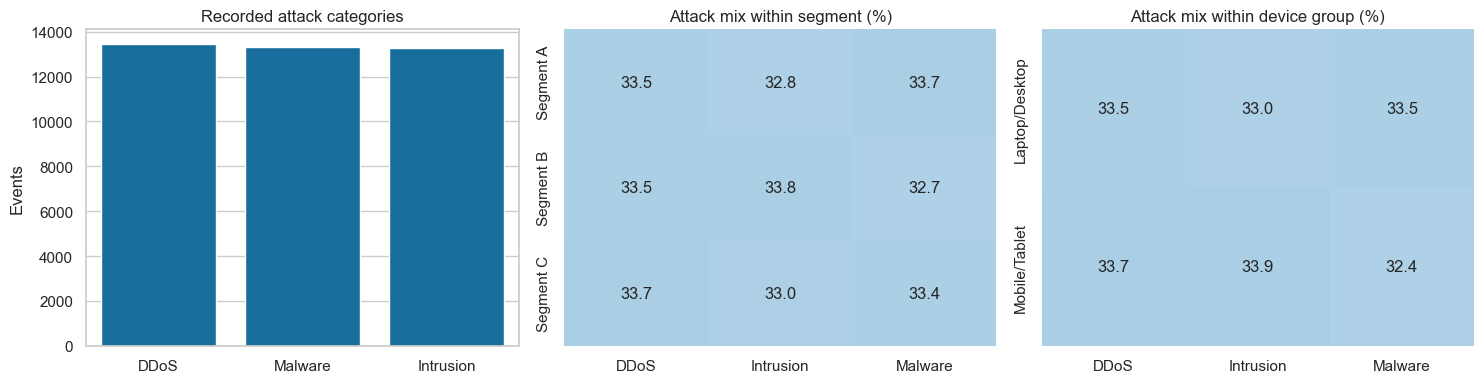

,events
network_segment,
Segment C,13408
Segment B,13319
Segment A,13273


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=events, x="attack_type", order=["DDoS", "Malware", "Intrusion"], ax=axes[0])
axes[0].set(title="Recorded attack categories", xlabel="", ylabel="Events")
segment_mix = pd.crosstab(events.network_segment, events.attack_type, normalize="index").mul(100)
sns.heatmap(segment_mix, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=axes[1], cbar=False)
axes[1].set(title="Attack mix within segment (%)", xlabel="", ylabel="")
device_mix = pd.crosstab(events.device_type, events.attack_type, normalize="index").mul(100)
sns.heatmap(device_mix, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=axes[2], cbar=False)
axes[2].set(title="Attack mix within device group (%)", xlabel="", ylabel="")
plt.tight_layout()
plt.show()
display(events.network_segment.value_counts().rename("events").to_frame())

A single in-memory SQLite table keeps the project small and reproducible. The table retains analytical fields but omits raw payloads, names, IPs, proxy addresses, and user-agent strings. No database file is required. The SQL file is the single source for the queries displayed below.

The segment query joins aggregated category counts to the overall category mix. This join supplies a meaningful comparison denominator without inventing a normalized schema.

In [6]:
connection = sqlite3.connect(":memory:")
sql_events = events.drop(columns=[
    "payload_data", "user_information", "source_ip_address", "destination_ip_address",
    "proxy_information", "device_information",
]).copy()
for column in ["timestamp", "event_date"]:
    sql_events[column] = sql_events[column].dt.strftime("%Y-%m-%d %H:%M:%S")
sql_events.to_sql("events", connection, index=False, if_exists="replace")

sql_text = (project_root / "sql/analysis.sql").read_text()
queries = dict(re.findall(r"-- name: (\w+)\n(.*?)(?=-- name: |\Z)", sql_text, flags=re.S))
assert len(queries) == 7
sql_results = {name: pd.read_sql_query(query, connection) for name, query in queries.items()}
assert sql_results["overview"].loc[0, "events"] == len(events)
assert sql_results["segment_mix"].events.sum() == len(events)
assert sql_results["severity_action"].events.sum() == len(events)
assert sql_results["monthly_activity"].events.sum() == len(events)
assert sql_results["state_rank"].events.sum() == len(events)
assert sql_results["protocol_mix"].events.sum() == events.anomaly_scores.gt(50).sum()
assert sql_results["high_severity_review"].high_severity_events.sum() == events.severity_level.eq("High").sum()
display(sql_results["overview"])
display(sql_results["segment_mix"])

,events,first_date,last_date,high_severity_pct,blocked_pct,high_ignored,high_ignored_pct
0,40000,2020-01-01,2023-10-11,33.45,33.82,4460,33.33


,network_segment,attack_type,events,segment_pct,overall_pct,difference_pp
0,Segment A,Malware,4479,33.75,33.27,0.48
1,Segment A,DDoS,4445,33.49,33.57,-0.08
2,Segment A,Intrusion,4349,32.77,33.16,-0.40
3,Segment B,Intrusion,4497,33.76,33.16,0.60
4,Segment B,DDoS,4466,33.53,33.57,-0.04
5,Segment B,Malware,4356,32.71,33.27,-0.56
6,Segment C,DDoS,4517,33.69,33.57,0.12
7,Segment C,Malware,4472,33.35,33.27,0.09
8,Segment C,Intrusion,4419,32.96,33.16,-0.20


In [7]:
largest_category = events.attack_type.value_counts().index[0]
max_mix_gap = sql_results["segment_mix"].difference_pp.abs().max()
display(Markdown(
    f"The largest category is **{largest_category}**, with "
    f"**{events.attack_type.value_counts().iloc[0]:,} events**. Across segment/category "
    f"combinations, the largest absolute departure from the overall mix is "
    f"**{max_mix_gap:.2f} percentage points**. These descriptive counts alone do not "
    "justify assigning different security priorities to the three segments."
))

The largest category is **DDoS**, with **13,428 events**. Across segment/category combinations, the largest absolute departure from the overall mix is **0.60 percentage points**. These descriptive counts alone do not justify assigning different security priorities to the three segments.

**Question 2: Does severity change the recorded response mix?** A high-severity event labeled Ignored is a useful candidate for a hypothetical case review. It is not proof of an analyst mistake: triage context, false positives, policies, and final outcomes are absent.

,severity_level,action_taken,events,within_severity_pct
0,High,Blocked,4530,33.85
1,High,Ignored,4460,33.33
2,High,Logged,4392,32.82
3,Low,Blocked,4481,33.99
4,Low,Ignored,4409,33.44
5,Low,Logged,4293,32.56
6,Medium,Blocked,4518,33.63
7,Medium,Ignored,4407,32.80
8,Medium,Logged,4510,33.57


,network_segment,high_severity_events,ignored,ignored_pct
0,Segment C,4523,1540,34.05
1,Segment B,4415,1481,33.54
2,Segment A,4444,1439,32.38


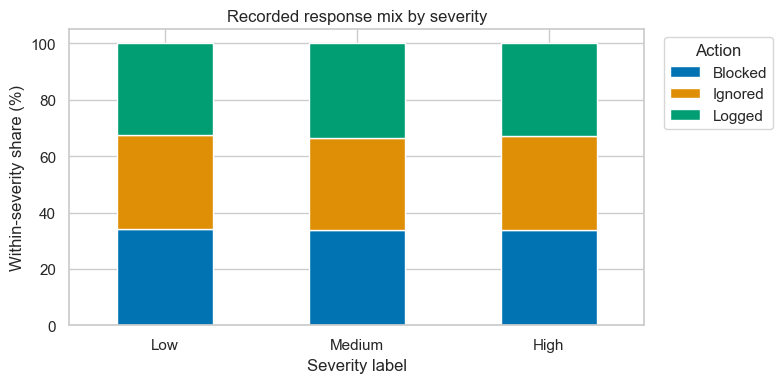

In [8]:
display(sql_results["severity_action"])
display(sql_results["high_severity_review"])
response_mix = pd.crosstab(events.severity_level, events.action_taken, normalize="index")
response_mix = response_mix.reindex(["Low", "Medium", "High"]).mul(100)
ax = response_mix.plot.bar(stacked=True, figsize=(8, 4), rot=0)
ax.set(title="Recorded response mix by severity", xlabel="Severity label", ylabel="Within-severity share (%)")
ax.legend(title="Action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Question 3: How does activity change over time?** Keep the final partial month visible, but exclude incomplete calendar months from comparisons of monthly totals. Compare response shares separately from volume. Observed date coverage is not proof of continuous monitoring, and month-to-month variation does not establish an operational improvement.

,month_start,events,blocked_pct,ignored_pct,complete_calendar_month,comparable_change_pct
40,2023-05-01,908,32.16,35.02,True,7.20
41,2023-06-01,863,35.23,31.75,True,-4.96
42,2023-07-01,889,32.96,33.63,True,3.01
43,2023-08-01,908,33.70,32.60,True,2.14
44,2023-09-01,853,34.58,32.47,True,-6.06
45,2023-10-01,296,38.85,30.74,False,NaN


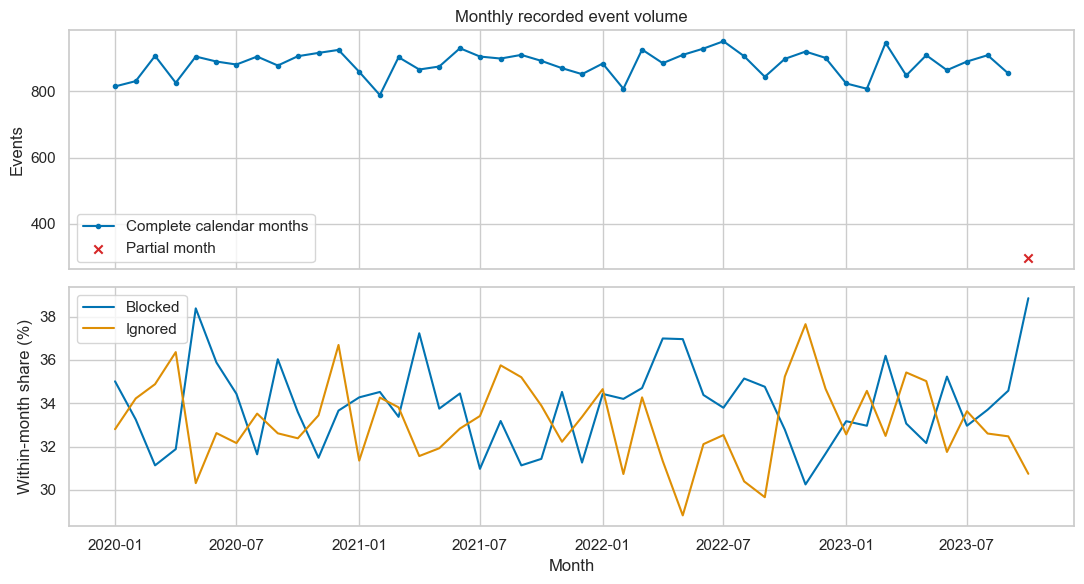

Complete months: 45; monthly events range 788–950.


In [9]:
monthly = sql_results["monthly_activity"].copy()
monthly["month_start"] = pd.to_datetime(monthly.month_start)
monthly["month_end"] = monthly.month_start + pd.offsets.MonthEnd(0)
monthly["complete_calendar_month"] = (
    monthly.month_start.ge(events.timestamp.min().normalize())
    & monthly.month_end.le(events.timestamp.max().normalize())
)
assert len(monthly) == len(pd.date_range(monthly.month_start.min(), monthly.month_start.max(), freq="MS"))
# A change touching an incomplete month is not a like-for-like volume comparison.
monthly["comparable_change_pct"] = monthly.change_pct.where(
    monthly.complete_calendar_month & monthly.complete_calendar_month.shift(1, fill_value=False)
)
display(monthly[["month_start", "events", "blocked_pct", "ignored_pct",
                 "complete_calendar_month", "comparable_change_pct"]].tail(6))

complete_months = monthly.loc[monthly.complete_calendar_month]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(complete_months.month_start, complete_months.events, marker=".", label="Complete calendar months")
partial = monthly.loc[~monthly.complete_calendar_month]
axes[0].scatter(partial.month_start, partial.events, marker="x", color="tab:red", label="Partial month")
axes[0].set(title="Monthly recorded event volume", ylabel="Events")
axes[0].legend()
axes[1].plot(monthly.month_start, monthly.blocked_pct, label="Blocked")
axes[1].plot(monthly.month_start, monthly.ignored_pct, label="Ignored")
axes[1].set(ylabel="Within-month share (%)", xlabel="Month")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Complete months: {len(complete_months)}; monthly events range "
      f"{complete_months.events.min():,}–{complete_months.events.max():,}.")

**Geographic drill-down:** Which state labels contribute the most recorded events? Aggregate once per state before joining to polygons. Audit unmatched labels and show missing data distinctly from zero. The provided boundaries are a visualization asset, not an authoritative current administrative reference. The map describes assigned state labels; it cannot establish geographic attack risk.

Event state labels absent from the map: []
Map labels without recorded events: ['Andaman and Nicobar Islands', 'Chandigarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Lakshadweep', 'Puducherry']
Map coverage: 40,000/40,000 events (100.0%)


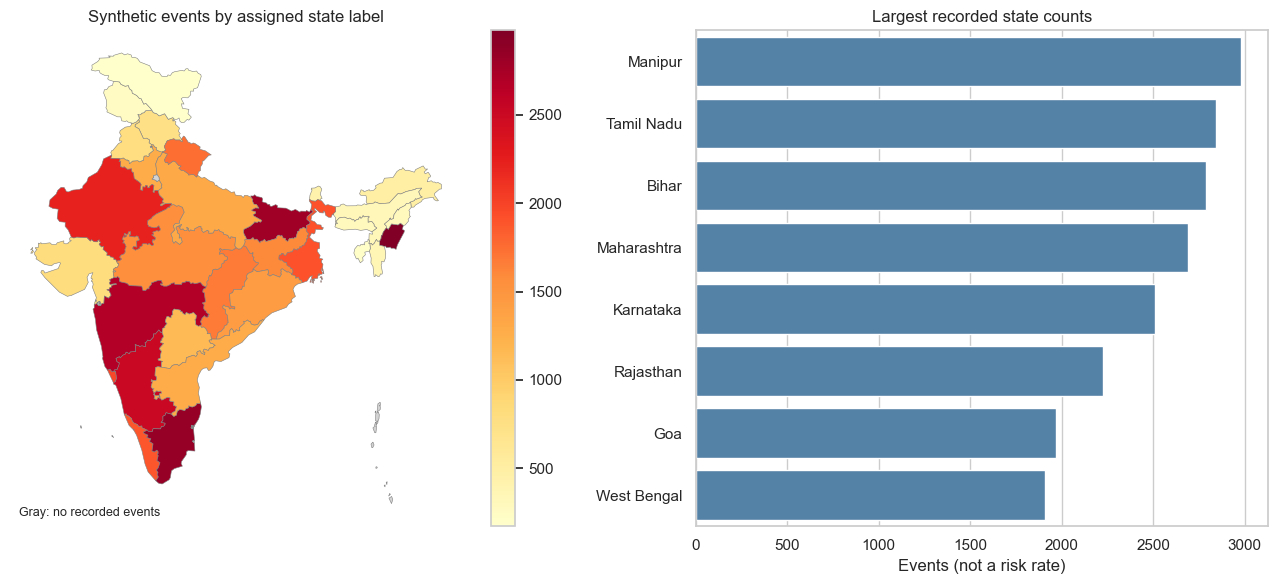

,location_state,events,event_pct,volume_rank
0,Manipur,2978,7.45,1
1,Tamil Nadu,2840,7.10,2
2,Bihar,2787,6.97,3
3,Maharashtra,2690,6.72,4
4,Karnataka,2509,6.27,5


In [10]:
state_counts = sql_results["state_rank"].copy()
india_map = gpd.read_file(project_root / "data/Indian_states.shp")
assert india_map.st_nm.is_unique, "Aggregate multipart state rows before joining."
unmatched_states = sorted(set(state_counts.location_state) - set(india_map.st_nm))
map_without_events = sorted(set(india_map.st_nm) - set(state_counts.location_state))
print("Event state labels absent from the map:", unmatched_states)
print("Map labels without recorded events:", map_without_events)
matched_events = state_counts.loc[state_counts.location_state.isin(india_map.st_nm), "events"].sum()
print(f"Map coverage: {matched_events:,}/{len(events):,} events ({matched_events / len(events):.1%})")

map_data = india_map.merge(state_counts, left_on="st_nm", right_on="location_state",
                           how="left", validate="one_to_one")
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
map_data.plot(column="events", cmap="YlOrRd", legend=True, linewidth=0.4,
              edgecolor="gray", missing_kwds={"color": "lightgray", "label": "No recorded events"}, ax=axes[0])
axes[0].set_title("Synthetic events by assigned state label")
axes[0].set_axis_off()
axes[0].text(0.02, 0.02, "Gray: no recorded events", transform=axes[0].transAxes, fontsize=9)
sns.barplot(data=state_counts.head(8), x="events", y="location_state", color="steelblue", ax=axes[1])
axes[1].set(title="Largest recorded state counts", xlabel="Events (not a risk rate)", ylabel="")
plt.tight_layout()
plt.show()
display(state_counts.head(5))

In [11]:
top_state = state_counts.iloc[0].location_state
state_drilldown = events.loc[events.location_state.eq(top_state)]
display(pd.crosstab([state_drilldown.device_type, state_drilldown.network_segment],
                    state_drilldown.attack_type, margins=True))
display(Markdown(
    f"**{top_state}** has the highest recorded count: **{len(state_drilldown):,}** "
    f"(**{len(state_drilldown) / len(events):.2%}** of events). The drill-down retains "
    "the original geographic investigation, but differences in customer or traffic exposure "
    "are unknown. No state or device group can be labeled more vulnerable from these counts."
))

attack_type                     DDoS  Intrusion  Malware   All
device_type    network_segment                                
Laptop/Desktop Segment A         270        258      275   803
               Segment B         264        263      229   756
               Segment C         256        243      264   763
Mobile/Tablet  Segment A          76         68       67   211
               Segment B          73         71       70   214
               Segment C          72         82       77   231
All                             1011        985      982  2978

**Manipur** has the highest recorded count: **2,978** (**7.45%** of events). The drill-down retains the original geographic investigation, but differences in customer or traffic exposure are unknown. No state or device group can be labeled more vulnerable from these counts.

## 3. Statistical Analysis
**Question 4: Are the apparent relationships stronger than sampling variation?** Three categorical comparisons address the SOC questions and the original protocol claim: attack type vs segment, severity vs action, and attack type vs protocol within high-anomaly events. Pearson's chi-square test compares observed and expected counts under independence. We report the smallest expected count and Cramér's V, since a small p-value alone does not establish a useful effect.

A fourth diagnostic uses Spearman correlation for anomaly score vs packet length, to check whether larger packets tend to receive higher anomaly scores, without imposing a linear relationship. Holm adjustment covers these four planned comparisons. Independence of rows is assumed for inference; synthetic generation, repeated entities, and undocumented event dependencies limit any population interpretation.

In [12]:
high_anomaly = events.loc[events.anomaly_scores.gt(50)].copy()
comparisons = [
    ("Attack type × segment", events, "attack_type", "network_segment"),
    ("Severity × action", events, "severity_level", "action_taken"),
    ("Attack type × protocol (score > 50)", high_anomaly, "attack_type", "protocol"),
]
test_rows = []
for label, frame, left, right in comparisons:
    table = pd.crosstab(frame[left], frame[right])
    chi2, p_value, dof, expected = stats.chi2_contingency(table, correction=False)
    assert expected.min() >= 5, "Use a different test for sparse expected cells."
    cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    test_rows.append({
        "comparison": label, "method": "Chi-square", "n": len(frame),
        "statistic": chi2, "df": dof, "p_value": p_value,
        "effect": cramers_v, "effect_name": "Cramér's V", "min_expected": expected.min(),
    })

rho, correlation_p = stats.spearmanr(events.anomaly_scores, events.packet_length)
test_rows.append({
    "comparison": "Anomaly score × packet length", "method": "Spearman", "n": len(events),
    "statistic": rho, "df": np.nan, "p_value": correlation_p,
    "effect": rho, "effect_name": "Spearman rho", "min_expected": np.nan,
})
statistical_results = pd.DataFrame(test_rows)
p_order = np.argsort(statistical_results.p_value.to_numpy())
ordered_p = statistical_results.p_value.to_numpy()[p_order]
adjusted = np.minimum(1, np.maximum.accumulate(ordered_p * np.arange(len(ordered_p), 0, -1)))
statistical_results["holm_p"] = np.nan
statistical_results.loc[p_order, "holm_p"] = adjusted
statistical_results["reject_at_0_05"] = statistical_results.holm_p.lt(0.05)
display(statistical_results.round(5))

,comparison,method,n,statistic,df,p_value,effect,effect_name,min_expected,holm_p,reject_at_0_05
0,Attack type × segment,Chi-square,40000,4.54574,4.0,0.33716,0.00754,Cramér's V,4401.65862,1.0,False
1,Severity × action,Chi-square,40000,3.41120,4.0,0.49151,0.00653,Cramér's V,4348.74212,1.0,False
2,Attack type × protocol (score > 50),Chi-square,20130,3.83808,4.0,0.42836,0.00976,Cramér's V,1717.50373,1.0,False
3,Anomaly score × packet length,Spearman,40000,-0.00364,NaN,0.46660,-0.00364,Spearman rho,NaN,1.0,False


The following interval quantifies uncertainty in the recorded proportion of high-severity events labeled Ignored. A Wilson interval behaves well for proportions and makes the denominator explicit. Treat it as an illustration conditional on an independent-event sampling model, not a confidence statement about real SOC activity.

In [13]:
def wilson_interval(successes, total, confidence=0.95):
    """Binomial proportion interval, conditional on independent observations."""
    z = stats.norm.ppf(0.5 + confidence / 2)
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    margin = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return center - margin, center + margin

high_severity_n = int(events.severity_level.eq("High").sum())
high_ignored_n = int((events.severity_level.eq("High") & events.action_taken.eq("Ignored")).sum())
high_ignored_interval = wilson_interval(high_ignored_n, high_severity_n)
print(f"High severity labeled Ignored: {high_ignored_n:,}/{high_severity_n:,} "
      f"= {high_ignored_n / high_severity_n:.2%}")
print(f"95% Wilson interval: {high_ignored_interval[0]:.2%}–{high_ignored_interval[1]:.2%}")

display(sql_results["protocol_mix"])
association_notes = []
for row in statistical_results.itertuples():
    conclusion = "reject independence at 5% after Holm adjustment" if row.reject_at_0_05 else "do not reject the null at 5% after Holm adjustment"
    association_notes.append(
        f"- **{row.comparison}:** {row.effect_name} = {row.effect:.4f}; "
        f"adjusted p = {row.holm_p:.4g}; {conclusion}."
    )
display(Markdown("\n".join(association_notes)))
display(Markdown(
    "Interpret statistical significance together with the effect size. Failure to reject is not proof "
    "of independence. Protocol prevalence within an attack category should be compared with overall "
    "protocol prevalence; a common protocol is not automatically a distinctive attack signature. "
    "None of these associations establishes causation or supports an ICMP blocking policy."
))

High severity labeled Ignored: 4,460/13,382 = 33.33%
95% Wilson interval: 32.53%–34.13%


,attack_type,protocol,events,within_attack_pct
0,DDoS,ICMP,3052,45.13
1,DDoS,TCP,1908,28.22
2,DDoS,UDP,1802,26.65
3,Intrusion,ICMP,3036,45.65
4,Intrusion,TCP,1931,29.04
5,Intrusion,UDP,1683,25.31
6,Malware,ICMP,3068,45.67
7,Malware,TCP,1936,28.82
8,Malware,UDP,1714,25.51


- **Attack type × segment:** Cramér's V = 0.0075; adjusted p = 1; do not reject the null at 5% after Holm adjustment.
- **Severity × action:** Cramér's V = 0.0065; adjusted p = 1; do not reject the null at 5% after Holm adjustment.
- **Attack type × protocol (score > 50):** Cramér's V = 0.0098; adjusted p = 1; do not reject the null at 5% after Holm adjustment.
- **Anomaly score × packet length:** Spearman rho = -0.0036; adjusted p = 1; do not reject the null at 5% after Holm adjustment.

Interpret statistical significance together with the effect size. Failure to reject is not proof of independence. Protocol prevalence within an attack category should be compared with overall protocol prevalence; a common protocol is not automatically a distinctive attack signature. None of these associations establishes causation or supports an ICMP blocking policy.

## 4. Feature Engineering and Machine Learning
**Question 5: Can protocol be predicted usefully in events with anomaly score > 50?** First reproduce the original implementation exactly: anomaly score plus three attack-type indicators, an unstratified 80/20 split with seed 42, and 100 default Random Forest trees. The majority baseline is fitted on the same training set and evaluated on the same holdout. This retrospective reproduction includes the original attack labels and is kept separate from the improved feature design.

In [14]:
original_features = pd.concat([
    high_anomaly[["anomaly_scores"]],
    pd.get_dummies(high_anomaly.attack_type, dtype=float)[["DDoS", "Malware", "Intrusion"]],
], axis=1)
original_target = high_anomaly.protocol.astype("category").cat.codes
original_x_train, original_x_test, original_y_train, original_y_test = train_test_split(
    original_features, original_target, test_size=0.2, random_state=SEED,
)
original_forest = RandomForestClassifier(n_estimators=100, random_state=SEED)
original_forest.fit(original_x_train, original_y_train)
original_predictions = original_forest.predict(original_x_test)
original_dummy = DummyClassifier(strategy="most_frequent")
original_dummy.fit(original_x_train, original_y_train)
original_dummy_predictions = original_dummy.predict(original_x_test)
reproduction = pd.DataFrame({
    "model": ["Original Random Forest", "Training-majority baseline"],
    "accuracy": [accuracy_score(original_y_test, original_predictions),
                 accuracy_score(original_y_test, original_dummy_predictions)],
    "macro_f1": [f1_score(original_y_test, original_predictions, average="macro"),
                 f1_score(original_y_test, original_dummy_predictions, average="macro")],
})
display(reproduction.round(6))
print(f"Eligible rows: {len(high_anomaly):,}; original test rows: {len(original_y_test):,}")
print(f"Accuracy difference from baseline: "
      f"{100 * (reproduction.loc[0, 'accuracy'] - reproduction.loc[1, 'accuracy']):.2f} percentage points")
print("Saved notebook reports 37.56% RF accuracy; 46.22% is the verified same-split majority baseline.")

,model,accuracy,macro_f1
0,Original Random Forest,0.375559,0.348512
1,Training-majority baseline,0.462245,0.210747


Eligible rows: 20,130; original test rows: 4,026
Accuracy difference from baseline: -8.67 percentage points
Saved notebook reports 37.56% RF accuracy; 46.22% is the verified same-split majority baseline.


Protocol is normally already present in network telemetry. Predicting it from these fields has limited SOC value and is a methodological exercise, not an attack detector. We keep the original target and anomaly threshold instead of changing targets to improve a score.

**Feature timing and leakage decisions**

| Fields | Decision and reason |
|---|---|
| Protocol and any protocol indicators | Target: never predictors |
| Attack type, signature, severity, response action | Exclude: labels or downstream annotations with undocumented timing |
| Malware/alert/log indicators, anomaly score | Detection timing is undocumented; retain anomaly score only because the task is explicitly retrospective and conditioned on that score; exclude the other indicators |
| Raw IPs, user names, payloads, city/state labels | Exclude: high cardinality, unverifiable meaning, or questionable geography; identifiers could encourage memorization |
| Packet length, ports, packet/traffic type, segment | Candidate observed fields; port/protocol inconsistency limits realism |
| Cyclic hour/month, weekday, port bands, OS family | Transparent derived features; compare against the simpler base feature set |

Deterministic row transformations above do not estimate parameters from other rows. Imputation, scaling, and category encoding below are fitted inside each training fold. A new **stratified** 80/20 split is used for all improved candidates, so their scores are comparable with one another but not a controlled improvement over the original unstratified split.

In [15]:
base_numeric = ["anomaly_scores", "packet_length", "source_port", "destination_port"]
base_categorical = ["packet_type", "traffic_type", "network_segment"]
engineered_numeric = base_numeric + ["hour_sin", "hour_cos", "month_sin", "month_cos"]
engineered_categorical = base_categorical + [
    "weekday", "source_port_band", "destination_port_band", "os_family",
]
all_features = engineered_numeric + engineered_categorical
X = high_anomaly[all_features].copy()
# Treat weekday as a category rather than imposing a linear Monday-to-Sunday effect.
X["weekday"] = X.weekday.astype(str)
y = high_anomaly.protocol.copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED,
)
assert set(X_train.index).isdisjoint(X_test.index)
for forbidden in ["protocol", "attack_type", "severity_level", "action_taken", "attack_signature"]:
    assert forbidden not in X.columns

display(pd.DataFrame({
    "all_pct": y.value_counts(normalize=True).mul(100),
    "train_pct": y_train.value_counts(normalize=True).mul(100),
    "test_pct": y_test.value_counts(normalize=True).mul(100),
}).round(2))
print(f"Training: {len(y_train):,}; untouched test: {len(y_test):,}")
display(X_train[engineered_numeric].describe().round(2))
display(pd.crosstab(X_train.os_family, y_train, normalize="index").round(3))

,all_pct,train_pct,test_pct
protocol,,,
ICMP,45.48,45.49,45.48
TCP,28.69,28.69,28.69
UDP,25.83,25.83,25.83


Training: 16,104; untouched test: 4,026


,anomaly_scores,packet_length,source_port,destination_port,hour_sin,hour_cos,month_sin,month_cos
count,16104.00,16104.00,16104.00,16104.00,16104.00,16104.00,16104.00,16104.00
mean,74.96,781.60,32986.29,33033.94,-0.00,0.00,0.04,-0.04
std,14.41,417.46,18492.82,18675.63,0.71,0.71,0.70,0.71
min,50.01,64.00,1030.00,1024.00,-1.00,-1.00,-1.00,-1.00
25%,62.59,419.00,17230.00,16746.50,-0.71,-0.71,-0.50,-0.87
50%,74.94,784.50,32720.50,32841.00,0.00,0.00,0.00,-0.00
75%,87.41,1144.00,48748.25,49281.00,0.71,0.71,0.87,0.50
max,99.99,1500.00,65530.00,65535.00,1.00,1.00,1.00,1.00


protocol,ICMP,TCP,UDP
os_family,,,
Android,0.471,0.279,0.250
Linux,0.456,0.281,0.263
Windows,0.456,0.289,0.255
iOS,0.448,0.291,0.261
macOS,0.448,0.287,0.265


Compare a majority DummyClassifier, Logistic Regression with base features, Logistic Regression with engineered features, and a Random Forest with engineered features. Logistic Regression tests a simple additive relationship; the forest tests nonlinear patterns. A fourth algorithm would add little without evidence of signal.

Use three identical stratified training folds. Tune only two regularization values per logistic model and two tree depths for the forest. **Macro-F1 is the prespecified selection metric** so that always predicting the largest class is not rewarded as a complete solution. Accuracy remains essential for evaluating practical benefit. Fold standard deviations describe split variation, not a confidence interval. The base-vs-engineered comparison tests whether the added features actually help.

In [16]:
def make_pipeline(numeric_columns, categorical_columns, estimator):
    """Keep preprocessing inside CV; use the same transformations for both model families."""
    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric_steps, numeric_columns),
        ("categorical", categorical_steps, categorical_columns),
    ])
    return Pipeline([("preprocessing", preprocessing), ("model", estimator)])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
fitted_models = {}
cv_rows = []

dummy = DummyClassifier(strategy="most_frequent")
dummy_cv = cross_validate(dummy, X_train, y_train, cv=cv, scoring=scoring)
fitted_models["Dummy majority"] = dummy.fit(X_train, y_train)
cv_rows.append({
    "model": "Dummy majority", "cv_accuracy": dummy_cv["test_accuracy"].mean(),
    "cv_macro_f1": dummy_cv["test_macro_f1"].mean(),
    "cv_f1_sd": dummy_cv["test_macro_f1"].std(ddof=1), "chosen_parameters": "most_frequent",
})

candidates = [
    ("Logistic base", base_numeric, base_categorical,
     LogisticRegression(max_iter=1000, random_state=SEED), {"model__C": [0.1, 1.0]}),
    ("Logistic engineered", engineered_numeric, engineered_categorical,
     LogisticRegression(max_iter=1000, random_state=SEED), {"model__C": [0.1, 1.0]}),
    ("Random Forest engineered", engineered_numeric, engineered_categorical,
     RandomForestClassifier(n_estimators=150, min_samples_leaf=10, random_state=SEED, n_jobs=1),
     {"model__max_depth": [6, None]}),
]
for name, numeric, categorical, estimator, parameters in candidates:
    search = GridSearchCV(
        make_pipeline(numeric, categorical, estimator), parameters,
        scoring=scoring, refit="macro_f1", cv=cv, n_jobs=1, error_score="raise",
    )
    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_
    best_index = search.best_index_
    cv_rows.append({
        "model": name,
        "cv_accuracy": search.cv_results_["mean_test_accuracy"][best_index],
        "cv_macro_f1": search.best_score_,
        "cv_f1_sd": search.cv_results_["std_test_macro_f1"][best_index] * np.sqrt(3 / 2),
        "chosen_parameters": str(search.best_params_),
    })
cv_results = pd.DataFrame(cv_rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
selected_name = cv_results.loc[0, "model"]
selected_model = fitted_models[selected_name]
display(cv_results.round(5))
print("Selected using training CV only:", selected_name)

,model,cv_accuracy,cv_macro_f1,cv_f1_sd,chosen_parameters
0,Random Forest engineered,0.45405,0.21079,0.00071,{'model__max_depth': None}
1,Dummy majority,0.45486,0.20843,0.00003,most_frequent
2,Logistic base,0.45486,0.20843,0.00003,{'model__C': 0.1}
3,Logistic engineered,0.45486,0.20843,0.00003,{'model__C': 0.1}


Selected using training CV only: Random Forest engineered


The selected model and all candidate settings are now frozen. Evaluate the holdout once for reporting. Precision, recall, and F1 are macro-averaged across ICMP/TCP/UDP with zero-division set to zero. The per-class report exposes whether the model largely ignores minority protocols.

,accuracy,macro_precision,macro_recall,macro_f1,accuracy_low,accuracy_high
model,,,,,,
Dummy majority,0.45479,0.15160,0.33333,0.20841,0.43946,0.47021
Logistic base,0.45479,0.15160,0.33333,0.20841,0.43946,0.47021
Logistic engineered,0.45479,0.15160,0.33333,0.20841,0.43946,0.47021
Random Forest engineered,0.45405,0.22855,0.33311,0.20994,0.43872,0.46946


,precision,recall,f1-score,support
ICMP,0.4549,0.9967,0.6247,1831.0
TCP,0.2308,0.0026,0.0051,1155.0
UDP,0.0000,0.0000,0.0000,1040.0
macro avg,0.2286,0.3331,0.2099,4026.0
weighted avg,0.2731,0.4540,0.2856,4026.0


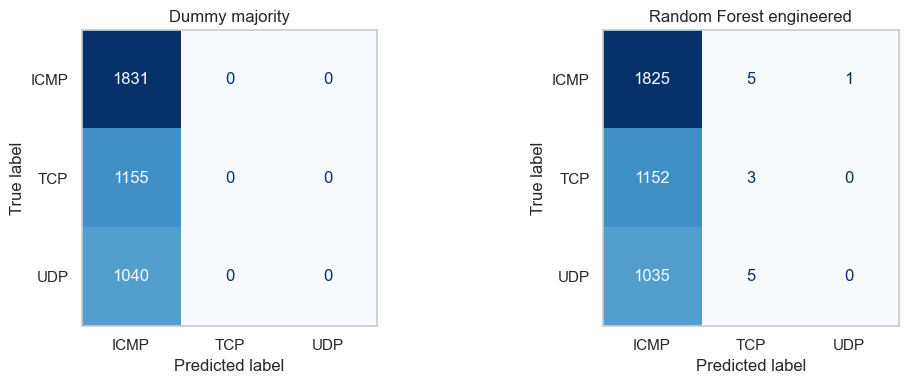

In [17]:
test_predictions = {}
evaluation_rows = []
for name, model in fitted_models.items():
    prediction = model.predict(X_test)
    test_predictions[name] = prediction
    correct = int(np.sum(prediction == y_test.to_numpy()))
    lower, upper = wilson_interval(correct, len(y_test))
    evaluation_rows.append({
        "model": name, "accuracy": accuracy_score(y_test, prediction),
        "macro_precision": precision_score(y_test, prediction, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, prediction, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, prediction, average="macro", zero_division=0),
        "accuracy_low": lower, "accuracy_high": upper,
    })
test_results = pd.DataFrame(evaluation_rows).set_index("model")
display(test_results.round(5))
selected_prediction = test_predictions[selected_name]
per_class_report = pd.DataFrame(classification_report(
    y_test, selected_prediction, output_dict=True, zero_division=0,
)).T
display(per_class_report.loc[["ICMP", "TCP", "UDP", "macro avg", "weighted avg"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, name in zip(axes, ["Dummy majority", selected_name]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[name], labels=["ICMP", "TCP", "UDP"],
        ax=axis, colorbar=False, cmap="Blues",
    )
    axis.set_title(name)
    axis.grid(False)
plt.tight_layout()
plt.show()

Compare the selected model with the dummy on the **same test rows**. A paired bootstrap resamples each row's correctness difference, preserving the paired predictions. Its percentile interval is conditional on this fitted model, this split, and independent rows; it does not measure training-set variability or establish external validity. It is exploratory evaluation, not another model-selection step.

In [18]:
paired_difference = (
    (selected_prediction == y_test.to_numpy()).astype(int)
    - (test_predictions["Dummy majority"] == y_test.to_numpy()).astype(int)
)
rng = np.random.default_rng(SEED)
bootstrap_differences = np.empty(2000)
for repeat in range(len(bootstrap_differences)):
    bootstrap_differences[repeat] = rng.choice(paired_difference, size=len(paired_difference), replace=True).mean()
accuracy_difference_interval = np.quantile(bootstrap_differences, [0.025, 0.975])
print(f"Selected minus dummy accuracy: {100 * paired_difference.mean():+.2f} percentage points")
print(f"Paired bootstrap 95% interval: {100 * accuracy_difference_interval[0]:+.2f} "
      f"to {100 * accuracy_difference_interval[1]:+.2f} percentage points")
engineered_cv = cv_results.set_index("model").loc["Logistic engineered", "cv_macro_f1"]
base_cv = cv_results.set_index("model").loc["Logistic base", "cv_macro_f1"]
print(f"Engineered minus base logistic CV macro-F1: {engineered_cv - base_cv:+.5f}")

Selected minus dummy accuracy: -0.07 percentage points
Paired bootstrap 95% interval: -0.22 to +0.07 percentage points
Engineered minus base logistic CV macro-F1: +0.00000


Permutation importance asks how much the selected model's holdout macro-F1 changes when a feature is shuffled. It is computed after selection and used only for interpretation. Three repeats on the full holdout keep the unshuffled and shuffled scores on the same rows; error bars show repeat standard deviations. Near-zero or negative importance is compatible with weak signal or random variation. Correlated derived/raw features can divide importance, so this is not a causal ranking.

,feature,mean_f1_decrease,repeat_sd
5,hour_cos,0.00092,0.00026
13,destination_port_band,0.00054,0.00042
4,hour_sin,0.00048,0.00068
9,traffic_type,0.00044,0.00036
12,source_port_band,0.00014,0.00023
11,weekday,0.00014,0.00062
7,month_cos,-0.00024,0.00094
2,source_port,-0.00025,0.00041
0,anomaly_scores,-0.00032,0.00077
6,month_sin,-0.00053,0.00040


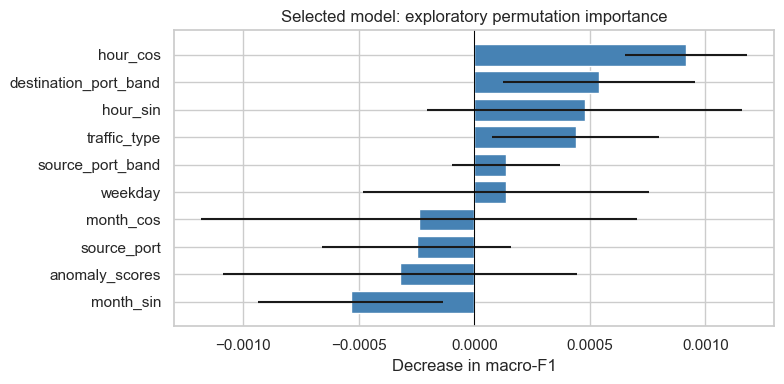

In [19]:
if selected_name != "Dummy majority":
    permutation = permutation_importance(
        selected_model, X_test, y_test, scoring="f1_macro", n_repeats=3,
        random_state=SEED, n_jobs=1,
    )
    feature_importance = pd.DataFrame({
        "feature": X_test.columns, "mean_f1_decrease": permutation.importances_mean,
        "repeat_sd": permutation.importances_std,
    }).sort_values("mean_f1_decrease", ascending=False)
    display(feature_importance.round(5))
    top_importance = feature_importance.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(top_importance.feature, top_importance.mean_f1_decrease,
            xerr=top_importance.repeat_sd, color="steelblue")
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set(title="Selected model: exploratory permutation importance", xlabel="Decrease in macro-F1")
    plt.tight_layout()
    plt.show()
else:
    feature_importance = pd.DataFrame()
    print("The dummy won training CV; feature importance is not meaningful.")

A random stratified split estimates performance only for similar records from this file. It is not a future-period or unseen-entity test. The features deliberately omit identities, but repeat users and other dependencies may remain. No claim about deployment follows from this comparison.

Poor results can arise because synthetic features are weakly related to protocol, predictors needed for protocol identification are absent, and the task predicts information already normally observed. Here the forest nearly collapses to the majority class: the per-class table shows almost no TCP recall and zero UDP recall. Both logistic feature sets produce the same majority predictions as the dummy. The engineered logistic features do not improve CV macro-F1. The forest's small macro-F1 advantage does not demonstrate useful protocol discrimination; the paired accuracy interval spans zero. Requiring at least ten observations per forest leaf limits fitting to small groups, but does not create evidence of predictive signal.

## 5. Findings, Recommendations, and Limitations
The following findings are generated from executed results so the conclusions stay tied to this dataset and model run.

In [20]:
overview = sql_results["overview"].iloc[0]
selected_scores = test_results.loc[selected_name]
dummy_scores = test_results.loc["Dummy majority"]
max_category_v = statistical_results.loc[statistical_results.method.eq("Chi-square"), "effect"].max()
best_test_accuracy_name = test_results.accuracy.idxmax()
findings = f"""
- **Coverage and quality:** {len(events):,} events, {raw.shape[1]} original columns, {duplicates_removed} duplicate rows removed; dates {events.timestamp.min():%Y-%m-%d}–{events.timestamp.max():%Y-%m-%d}. Six optional source fields contain blanks. All {icmp_with_ports:,} ICMP rows have populated port fields, limiting network realism.
- **Event distribution:** {largest_category} is the largest category ({events.attack_type.value_counts().iloc[0]:,}; {events.attack_type.value_counts().iloc[0] / len(events):.2%}). The largest segment-mix departure is {max_mix_gap:.2f} percentage points. {top_state} contributes {len(state_drilldown):,} assigned events ({len(state_drilldown) / len(events):.2%}), a volume measure without an exposure denominator.
- **Response review:** {high_ignored_n:,}/{high_severity_n:,} high-severity events are labeled Ignored ({high_ignored_n / high_severity_n:.2%}; illustrative 95% Wilson interval {high_ignored_interval[0]:.2%}–{high_ignored_interval[1]:.2%}). Blocked labels account for {overview.blocked_pct:.2f}% of all events; this is not a prevention success rate.
- **Time:** {len(complete_months)} complete calendar months contain {complete_months.events.min():,}–{complete_months.events.max():,} events each. The final month is partial and excluded from volume comparisons. No causal explanation for seasonal changes is identified.
- **Statistics:** the largest of the three categorical Cramér's V values is {max_category_v:.4f}; the full test table reports adjusted p-values and expected counts. Spearman rho for anomaly score vs packet length is {rho:.4f}. Statistical and operational relevance must be assessed separately.
- **Original model verified:** RF accuracy {reproduction.loc[0, 'accuracy']:.2%} versus same-split majority accuracy {reproduction.loc[1, 'accuracy']:.2%}.
- **Fair comparison:** training CV selected **{selected_name}** by macro-F1. Its test accuracy is {selected_scores.accuracy:.2%}, macro-precision {selected_scores.macro_precision:.4f}, macro-recall {selected_scores.macro_recall:.4f}, and macro-F1 {selected_scores.macro_f1:.4f}; dummy test accuracy is {dummy_scores.accuracy:.2%} and macro-F1 {dummy_scores.macro_f1:.4f}. The highest holdout accuracy belongs to **{best_test_accuracy_name}**; holdout scores did not determine selection.
- **Uncertainty:** selected-minus-dummy accuracy is {100 * paired_difference.mean():+.2f} percentage points, with paired bootstrap interval {100 * accuracy_difference_interval[0]:+.2f} to {100 * accuracy_difference_interval[1]:+.2f} percentage points. Added logistic features change CV macro-F1 by {engineered_cv - base_cv:+.5f}; this is an observed ablation result, not proof of a general improvement.
"""
display(Markdown(findings))


- **Coverage and quality:** 40,000 events, 25 original columns, 0 duplicate rows removed; dates 2020-01-01–2023-10-11. Six optional source fields contain blanks. All 18,370 ICMP rows have populated port fields, limiting network realism.
- **Event distribution:** DDoS is the largest category (13,428; 33.57%). The largest segment-mix departure is 0.60 percentage points. Manipur contributes 2,978 assigned events (7.45%), a volume measure without an exposure denominator.
- **Response review:** 4,460/13,382 high-severity events are labeled Ignored (33.33%; illustrative 95% Wilson interval 32.53%–34.13%). Blocked labels account for 33.82% of all events; this is not a prevention success rate.
- **Time:** 45 complete calendar months contain 788–950 events each. The final month is partial and excluded from volume comparisons. No causal explanation for seasonal changes is identified.
- **Statistics:** the largest of the three categorical Cramér's V values is 0.0098; the full test table reports adjusted p-values and expected counts. Spearman rho for anomaly score vs packet length is -0.0036. Statistical and operational relevance must be assessed separately.
- **Original model verified:** RF accuracy 37.56% versus same-split majority accuracy 46.22%.
- **Fair comparison:** training CV selected **Random Forest engineered** by macro-F1. Its test accuracy is 45.40%, macro-precision 0.2286, macro-recall 0.3331, and macro-F1 0.2099; dummy test accuracy is 45.48% and macro-F1 0.2084. The highest holdout accuracy belongs to **Dummy majority**; holdout scores did not determine selection.
- **Uncertainty:** selected-minus-dummy accuracy is -0.07 percentage points, with paired bootstrap interval -0.22 to +0.07 percentage points. Added logistic features change CV macro-F1 by +0.00000; this is an observed ablation result, not proof of a general improvement.


**Recommendations for a hypothetical SOC**

1. Use the high-severity/Ignored breakdown to define a case-review exercise. Real action would require disposition reasons, false-positive labels, policy context, and final incident outcomes.
2. Add monitored endpoint counts or traffic volumes before prioritizing states, devices, or segments. Recorded event totals alone cannot rank vulnerability or risk.
3. Track response shares alongside event volumes and monitoring coverage. Preserve incomplete-period flags; a larger Blocked count is not evidence of more effective prevention.
4. Keep protocol prediction as a benchmark exercise. Before any operational model, collect a justified target with known label timing, validate on later dates and separated entities, and compare it with an appropriate simple baseline. Do not derive an ICMP blocking rule from this synthetic file.

**Limits of the evidence**

Synthetic generation is undocumented, labels lack verification, and no benign class or exposure denominator is available. Blank optional fields have ambiguous meaning. Device labels are heuristic; geographic labels and the supplied boundaries are unverified. Port fields conflict with ICMP semantics. Event independence is unproven, so inferential intervals and tests are conditional illustrations. The model comparison uses one random split and three training folds, a deliberately small search, and no external or future-period validation. Selecting on training CV can still produce optimistic CV scores. Importance is exploratory and potentially shared across correlated features. No real security effectiveness, causal effect, or savings is demonstrated.

In [21]:
connection.close()
print("Notebook completed; SQLite connection closed. All source files were read only.")

Notebook completed; SQLite connection closed. All source files were read only.
